# 예측 모델 0~4단계 (A, 강민주)

노션 '분석 설계 8.3'의 단계별 모델을 비교한다. Train(2022~23, 2023~24 겨울, 2023, 2024 여름)으로 학습하고 Dev(2024~25 겨울, 2025 여름)로만 평가한다. Test는 열지 않는다.

| 단계 | 모델 | 입력 |
| --- | --- | --- |
| 0 | 평소값 (비율 = 1) | 없음 |
| 1 | 직전 상태 유지 (y_hat = ratio_t0) | t 시점 비율 |
| 2 | 선형회귀 | (1) 도로 (2) 시간 (3) 최근 상태 |
| 3 | CatBoost | 같은 입력, 날씨 없음 |
| 4 | CatBoost | 3단계 입력 + (4) 관측 날씨, 한강 수위 (5) 특보 |

- 예보, AWS는 5단계에서 넣는다.
- 악천후 가중치는 1, 2, 3배를 3, 4단계 모두 같은 조건으로 비교했고, 1배(없음)로 확정했다 (11/27 합의).
- 계산은 `src/analysis/prediction.py`가 하고, 이 노트북은 저장된 결과를 읽어서 보여 준다.

In [1]:
RUN_BUILD = False  # True로 바꿀 때만 학습, 평가를 다시 돌려 결과 파일을 덮어쓴다 (몇 분 걸림)

import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == '02_analysis' else Path.cwd()
plt.rcParams['font.family'] = 'Malgun Gothic'  # 윈도우 한글 글꼴
plt.rcParams['axes.unicode_minus'] = False

if RUN_BUILD:
    subprocess.run([sys.executable, str(ROOT / 'src' / 'analysis' / 'prediction.py')], check=True, cwd=ROOT)
else:
    print('RUN_BUILD = False (저장된 결과를 읽기만)')

m = pd.read_csv(ROOT / 'outputs' / 'tables' / 'prediction_dev_metrics.csv')
log = json.loads((ROOT / 'logs' / 'kmj' / 'prediction' / 'prediction.json').read_text(encoding='utf-8'))
print('실행:', log['run_at'], '| 행 수:', log['rows'], '| 정답 빈 행 제외:', log['dropped_no_target'])

STAGES = ['0_평소값', '1_직전상태', '2_선형회귀', '3_CatBoost', '4_CatBoost_날씨']
CB = ['3_CatBoost', '4_CatBoost_날씨']


def view(gtype, horizon='3', stages=STAGES, value='mae_min'):
    t = m[(m['group_type'] == gtype) & (m['horizon'] == horizon) & m['stage'].isin(stages)]
    return t.pivot(index='stage', columns='group', values=value).reindex(stages)


def change(t, base='3_CatBoost', new='4_CatBoost_날씨'):
    return ((t.loc[new] / t.loc[base] - 1) * 100).round(1).rename('4단계 vs 3단계 (%)')

RUN_BUILD = False (저장된 결과를 읽기만)
실행: 2026-11-27T22:02:24+09:00 | 행 수: {'train': 592972, 'dev': 291296, 'train_seasons': ['2022-23_winter', '2023-24_winter', '2023_summer', '2024_summer'], 'dev_seasons': ['2024-25_winter', '2025_summer']} | 정답 빈 행 제외: 1332


## 1. 전체 (Dev)

주 지표는 h = 3 MAE(분). 분 = |예측 비율 - 실제 비율| x 입력용 평소 통행시간 / 60

In [2]:
cols = ['stage', 'horizon', 'n_rows', 'mae_min', 'rmse_min', 'mae_ratio', 'rmse_ratio']
m[(m['group_type'] == '전체') & m['stage'].isin(STAGES)][cols].sort_values(['horizon', 'stage']).round(3)

,stage,horizon,n_rows,mae_min,rmse_min,mae_ratio,rmse_ratio
33,0_평소값,1,145648,1.481,3.260,0.082,0.153
132,1_직전상태,1,145648,1.087,2.129,0.067,0.122
231,2_선형회귀,1,145648,1.022,2.039,0.062,0.113
330,3_CatBoost,1,145648,0.972,2.010,0.059,0.112
429,4_CatBoost_날씨,1,145648,0.982,2.045,0.060,0.113
66,0_평소값,3,145648,1.481,3.260,0.082,0.153
165,1_직전상태,3,145648,1.414,2.945,0.083,0.150
264,2_선형회귀,3,145648,1.297,2.766,0.075,0.138
363,3_CatBoost,3,145648,1.203,2.621,0.071,0.133
462,4_CatBoost_날씨,3,145648,1.197,2.570,0.071,0.132


## 2. 날씨 구분별 (h = 3)

시간 수 = 겹치지 않는 (날짜, 목표 시각) 수. 악천후, 약한 비·눈은 시간 수가 적어 작은 차이는 크게 읽지 않는다.

In [3]:
w = view('날씨')
display(w.round(3))
display(change(w).to_frame().T)
m[(m['group_type'] == '날씨') & (m['horizon'] == '3')].drop_duplicates('group')[['group', 'n_rows', 'n_hours']]

group,맑음,악천후,약한 비·눈
stage,,,
0_평소값,1.276,2.650,1.685
1_직전상태,1.257,2.312,1.552
2_선형회귀,1.139,2.207,1.421
3_CatBoost,1.046,2.075,1.390
4_CatBoost_날씨,1.056,1.974,1.377


group,맑음,악천후,약한 비·눈
4단계 vs 3단계 (%),0.9,-4.9,-0.9


,group,n_rows,n_hours
67,맑음,117407,653
68,악천후,19066,106
69,약한 비·눈,9175,51


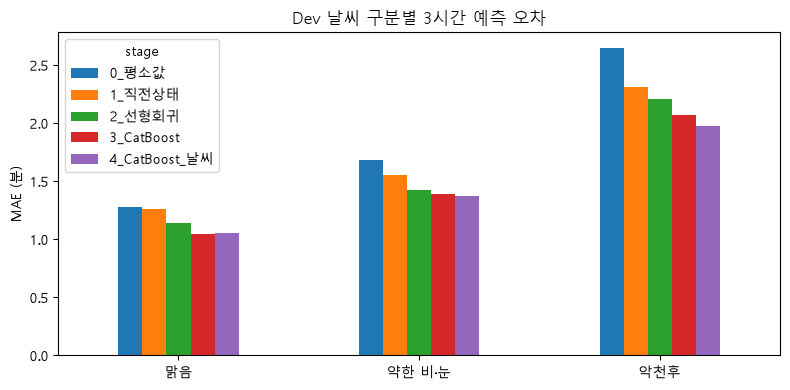

In [4]:
ax = w.T.loc[['맑음', '약한 비·눈', '악천후']].plot.bar(rot=0, figsize=(8, 4))
ax.set_ylabel('MAE (분)')
ax.set_xlabel('')
ax.set_title('Dev 날씨 구분별 3시간 예측 오차')
plt.tight_layout()

## 3. 악천후 가중치 비교 (3, 4단계 모두)

'내리는 중인 악천후' 시간(눈은 snow_phase == falling, 비는 관측 강수 > 0)의 학습 오차를 1, 2, 3배로 쳤다.
4단계 성적만 보고 고르면 4단계에 유리하게 고른 것이 되므로, 가중치마다 3단계와 4단계를 같이 둔다.
고르는 기준은 돌리기 전에 정했다: 악천후 MAE가 가장 낮은 값, 단 전체 MAE가 1배보다 5% 넘게 나빠지면 제외.

In [5]:
print('기준:', log['weight_rule'], '| 고른 값:', log['picked_weight'],
      '| 가중치를 받은 학습 행 비율:', log['weighted_train_share'])
rows = []
for h in ['3', '전체']:
    for wt in [1, 2, 3]:
        names = {st: st if wt == 1 else f'{st}_가중{wt}' for st in CB}
        t = pd.concat([view(g, h, list(names.values())) for g in ['전체', '날씨', '눈비']], axis=1)
        s3, s4 = t.loc[names['3_CatBoost']], t.loc[names['4_CatBoost_날씨']]
        rows.append({'h': h, '가중치': wt, '3단계 악천후': s3['악천후'], '4단계 악천후': s4['악천후'],
                     '4 vs 3 악천후 (%)': (s4['악천후'] / s3['악천후'] - 1) * 100,
                     '3단계 맑음': s3['맑음'], '4단계 맑음': s4['맑음'],
                     '3단계 전체': s3['전체'], '4단계 전체': s4['전체']})
pd.DataFrame(rows).round(3)

기준: 악천후 MAE 최소, 전체 MAE가 1배보다 5% 넘게 나빠지면 제외 | 고른 값: {'3_CatBoost': 1, '4_CatBoost_날씨': 1} | 가중치를 받은 학습 행 비율: 0.0751


,h,가중치,3단계 악천후,4단계 악천후,4 vs 3 악천후 (%),3단계 맑음,4단계 맑음,3단계 전체,4단계 전체
0,3,1,2.075,1.974,-4.873,1.046,1.056,1.203,1.197
1,3,2,2.067,1.963,-5.027,1.049,1.061,1.204,1.198
2,3,3,2.062,1.983,-3.826,1.051,1.068,1.205,1.206
3,전체,1,1.746,1.694,-3.012,0.967,0.978,1.087,1.089
4,전체,2,1.748,1.694,-3.100,0.971,0.981,1.091,1.091
5,전체,3,1.753,1.713,-2.299,0.973,0.985,1.093,1.096


가중치를 키워도 악천후 오차는 거의 그대로이고 맑음은 조금씩 나빠진다. 가중치가 몇 배든 4단계가 3단계보다 악천후 오차가 낮다.

## 4. 큰 지연, '20% 이상 느려짐' (h = 3)

평균 MAE에는 드문 큰 지연이 묻힌다. 실제 1.3배 이상인 행의 MAE와, 실제 1.2배 이상 느려진 행을 맞혔는지(적중률),
느려진다고 한 것 중 맞은 비율(정밀도)을 따로 본다.

In [6]:
big = m[(m['group_type'] == '날씨') & (m['horizon'] == '3') & m['stage'].isin(STAGES)]
big = big[['stage', 'group', 'n_big', 'mae_min_big', 'n_slow', 'slow_recall', 'slow_precision', 'mean_y', 'mean_pred']]
big.sort_values(['group', 'stage']).round(3)

,stage,group,n_big,mae_min_big,n_slow,slow_recall,slow_precision,mean_y,mean_pred
67,0_평소값,맑음,2507,7.877,5380,0.000,NaN,1.012,1.000
166,1_직전상태,맑음,2507,6.119,5380,0.154,0.334,1.012,1.008
265,2_선형회귀,맑음,2507,6.260,5380,0.081,0.492,1.012,1.012
364,3_CatBoost,맑음,2507,5.813,5380,0.125,0.592,1.012,1.012
463,4_CatBoost_날씨,맑음,2507,5.725,5380,0.137,0.519,1.012,1.015
68,0_평소값,악천후,1567,11.121,2670,0.000,NaN,1.052,1.000
167,1_직전상태,악천후,1567,8.257,2670,0.224,0.474,1.052,1.032
266,2_선형회귀,악천후,1567,8.464,2670,0.160,0.491,1.052,1.037
365,3_CatBoost,악천후,1567,8.296,2670,0.170,0.572,1.052,1.037
464,4_CatBoost_날씨,악천후,1567,8.426,2670,0.140,0.648,1.052,1.027


In [7]:
pred = pd.read_parquet(ROOT / 'data' / 'derived' / 'prediction' / 'dev_predictions.parquet')
b = pred[(pred['y_ratio'] >= 1.3) & (pred['weather_class'] == '악천후')]
b.groupby('horizon')[['y_ratio'] + [f'pred_{s}' for s in CB]].mean().round(3)

,y_ratio,pred_3_CatBoost,pred_4_CatBoost_날씨
horizon,,,
1,1.601,1.289,1.286
3,1.601,1.140,1.133


악천후 큰 지연 시간의 실제 평균은 1.6배인데 예측 평균은 1.1~1.3배라 체계적으로 낮다. 가중치로도 바뀌지 않았다.
큰 지연은 정체 경보 모델(분류)이 맡는다 (11/27 합의).

## 5. 나눠 보기 (h = 3): 눈, 비, 계절, 출퇴근, 날씨 x 출퇴근, 평소값 대체

In [8]:
for gtype in ['눈비', '계절', '출퇴근', '날씨x출퇴근', '평소값']:
    t = view(gtype)
    print(f'[{gtype}]')
    display(t.round(3))
    display(change(t).to_frame().T)

[눈비]


group,눈,비
stage,,
0_평소값,2.835,2.154
1_직전상태,2.616,1.864
2_선형회귀,2.501,1.751
3_CatBoost,2.395,1.654
4_CatBoost_날씨,2.080,1.670


group,눈,비
4단계 vs 3단계 (%),-13.1,1.0


[계절]


group,summer,winter
stage,,
0_평소값,1.444,1.533
1_직전상태,1.387,1.451
2_선형회귀,1.262,1.347
3_CatBoost,1.169,1.250
4_CatBoost_날씨,1.188,1.210


group,summer,winter
4단계 vs 3단계 (%),1.6,-3.3


... (5 outputs left out)

group,맑음 x 출근,맑음 x 퇴근,악천후 x 출근,악천후 x 퇴근,약한 비·눈 x 출근,약한 비·눈 x 퇴근
4단계 vs 3단계 (%),0.5,1.1,-6.2,-4.4,-0.7,-1.0


[평소값]


group,28일
stage,
0_평소값,1.481
1_직전상태,1.414
2_선형회귀,1.297
3_CatBoost,1.203
4_CatBoost_날씨,1.197


group,28일
4단계 vs 3단계 (%),-0.5


## 6. 반복 취약 도로, 방향 (h = 3)

`data/shared/train_dev/vulnerable_roads_train_dev.csv`의 비 취약 9개, 눈 취약 4개(도로, 방향). 올림픽대로 상행은 둘 다라서 '눈·비 취약'.

주의: 이 목록은 Train과 Dev 사건을 합쳐서 만들었다. 그래서 Dev 오차의 크기 자체보다 '같은 도로에서 3단계 -> 4단계가 얼마나 나아졌나'만 참고로 본다.

In [9]:
vw = m[(m['group_type'] == '취약도로x날씨') & (m['horizon'] == '3') & m['stage'].isin(CB)]
t = vw.pivot(index='group', columns='stage', values='mae_min')[CB]
t['4 vs 3 (%)'] = ((t['4_CatBoost_날씨'] / t['3_CatBoost'] - 1) * 100).round(1)
t['행 수'] = vw.drop_duplicates('group').set_index('group')['n_rows']
t.round(3)

stage,3_CatBoost,4_CatBoost_날씨,4 vs 3 (%),행 수
group,,,,
나머지 x 맑음,0.884,0.892,0.9,109605
나머지 x 악천후,1.704,1.626,-4.6,17801
나머지 x 약한 비·눈,1.139,1.136,-0.2,8566
눈 취약 x 맑음,1.830,1.855,1.4,1959
눈 취약 x 악천후,3.913,3.798,-3.0,315
눈 취약 x 약한 비·눈,2.311,2.243,-2.9,153
눈·비 취약 x 맑음,5.404,5.418,0.3,652
눈·비 취약 x 악천후,14.627,13.620,-6.9,106
눈·비 취약 x 약한 비·눈,9.064,8.628,-4.8,51


## 7. CatBoost 변수 중요도 (3, 4단계, 가중치 없음)

In [10]:
imp = pd.DataFrame({s: pd.Series(log['catboost_importance'][s]) for s in CB}).fillna(0)
imp.sort_values('4_CatBoost_날씨', ascending=False).head(15).round(2)

,3_CatBoost,4_CatBoost_날씨
ratio_t0,24.62,24.65
type_ratio_t0,12.03,11.84
city_ratio_t0,11.55,8.28
target_hour,8.33,7.23
lanes,6.97,6.76
total_distance_m,7.09,6.31
weekday,5.70,5.01
month,5.90,4.16
temp_c,0.00,3.63
horizon,4.22,3.45


## 정리 (Dev)

1. 4단계(관측 날씨, 수위, 특보)는 h = 3 악천후 오차를 3단계보다 줄였지만 성공 기준(10%)에는 못 미친다. 기준은 Test에서 판정하므로 바꾸지 않는다.
2. 가중치는 1배(없음)로 확정. 3, 4, 5단계 모두 같은 조건.
3. 큰 지연은 체계적으로 낮게 예측한다 -> 큰 지연은 정체 경보 모델(분류)이 맡는다.
4. 다음: 5단계(예보, AWS 추가), SHAP.